# Heart Disease Prediction Using Machine Learning

## 1. Project Introduction

Cardiovascular diseases are one of the major causes of death worldwide. Early identification of potential heart disease risk can help healthcare professionals take preventive measures and improve patient care.

This project focuses on analyzing patient health information and developing machine learning classification models to predict the presence of heart disease.

The dataset contains medical attributes such as age, blood pressure, cholesterol, chest pain type, maximum heart rate and exercise-induced angina.

The project involves data analysis, preprocessing, machine learning model development, performance comparison and providing recommendations to hospitals.

**Domain:** Healthcare

**Project Type:** Binary Classification


## 2. Problem Statement and Objectives

### Problem Statement

The objective is to analyze patient health information and develop a machine learning model to predict the potential presence of heart disease.

### Objectives

1. Perform exploratory data analysis to understand patient health characteristics.
2. Clean and preprocess the dataset for machine learning.
3. Develop multiple classification models to predict heart disease.
4. Evaluate and compare model performance to identify the most suitable model.
5. Provide recommendations to hospitals for early risk identification and preventive healthcare.

## 3. Dataset Description

The dataset contains patient-related medical information used to predict the presence of heart disease.

It consists of two separate files: a patient medical features file and a target file. The medical features file contains 14 columns, including one unique patient identifier (patient_id) and 13 medical features.

The input features describe patient characteristics, medical measurements and exercise-related observations.

**Target Variable:** `heart_disease_present`

- 0 – No heart disease
- 1 – Heart disease present

**Dataset Files:**
- Values file: Contains patient medical features.
- Labels file: Contains patient identifiers and corresponding target values.

The two files will be combined using the common `patient_id` column.

## 4. Importing Required Libraries

Required Python libraries are imported for data manipulation, numerical operations, data visualization, data preprocessing, machine learning, and model evaluation. Warning handling and display settings are also configured.

In [20]:
# 1. Data Manipulation

import pandas as pd 
import numpy as np 

# 2. Data Visualization 

import matplotlib.pyplot as plt 
import seaborn as sns

# 3. Data Preprocessing 

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 4. MACHINE LEARNING ALGORITHMS 

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier 
from sklearn.svm import SVC 
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.naive_bayes import GaussianNB

# 5. MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report)

# 6. WARNING HANDLING

import warnings
warnings.filterwarnings("ignore")

# 7. DISPLAY SETTINGS

pd.set_option("display.max_columns", None)

print("All required libraries imported successfully!")


All required libraries imported successfully!


## 5. Loading the Datasets

The dataset is provided in two separate Excel files: one containing patient medical information and the other containing the corresponding target labels.

Both files are loaded using Pandas to prepare them for further analysis and merging.

In [21]:
# Load the datasets
df_values = pd.read_csv("values.csv")
df_labels=pd.read_csv("labels.csv")

# Display dataset dimensions 
print("Values Dataset:",df_values.shape)
print("Label Dataset:",df_labels.shape)


Values Dataset: (180, 14)
Label Dataset: (180, 2)


**FINDING**:

The values dataset contains 180 records and 14 columns, while the labels dataset contains 180 records and 2 columns. Both datasets have an equal number of patient records and are ready for further inspection and merging.

### 5. Data Integration

The values and labels datasets are combined using the common patient_id column. Before merging, duplicate and unmatched patient IDs are checked to ensure data consistency.

In [22]:
# Check duplicate IDs
print("Duplicate IDs:",
      df_values["patient_id"].duplicated().sum(),
      df_labels["patient_id"].duplicated().sum())

# Merge datasets
df= pd.merge(df_values,df_labels,on="patient_id",how="inner")
display(df.head())

Duplicate IDs: 0 0


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


**FINDING**:

No duplicate patient IDs were found in either dataset. Both datasets were successfully merged 
using patient_id, combining patient medical information with the corresponding heart disease labels.

## 6. Initial Data Understanding

In this step, we examine the structure, data types, missing values and basic statistical summary of the merged dataset to understand its quality and characteristics.

In [23]:
# Dataset information 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [24]:
# Check missing values
print("\nMissing Values:")
display(df.isnull().sum())


Missing Values:


patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [25]:
# Statistical summary
display(df.describe())

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


**FINDING**: 

The dataset contains 180 patient records with no missing values.

The average age of patients is 54.81 years.

The average resting blood pressure is 131.31 mmHg.

The average serum cholesterol level is 249.21 mg/dL.

The average maximum heart rate achieved is 149.48 bpm.

The average ST depression value is 1.01.

The average target value is 0.4444, indicating that 44.44% of records belong to the heart disease class.

## 6. Data Cleaning

Data cleaning is performed to ensure the dataset is accurate and consistent before analysis and model development. In this section, we check for duplicate records, missing values and data types, and identify unnecessary columns.

In [26]:
# Check duplicate rows
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [27]:
# Check Unique Values in Categorical Columns 
print("Thal Categories:", df["thal"].unique())

print("Target Categories:",
      df["heart_disease_present"].unique())

Thal Categories: ['normal' 'reversible_defect' 'fixed_defect']
Target Categories: [0 1]


**FINDING**

No duplicate records were found.

The thal feature contains three categories: normal, reversible defect and fixed defect.

The target variable contains two classes: 0 and 1.

## 7. Exploratory Data Analysis (EDA)

EDA is performed to understand the distribution of patient health features, identify patterns and explore relationships between medical attributes and heart disease using visualizations.

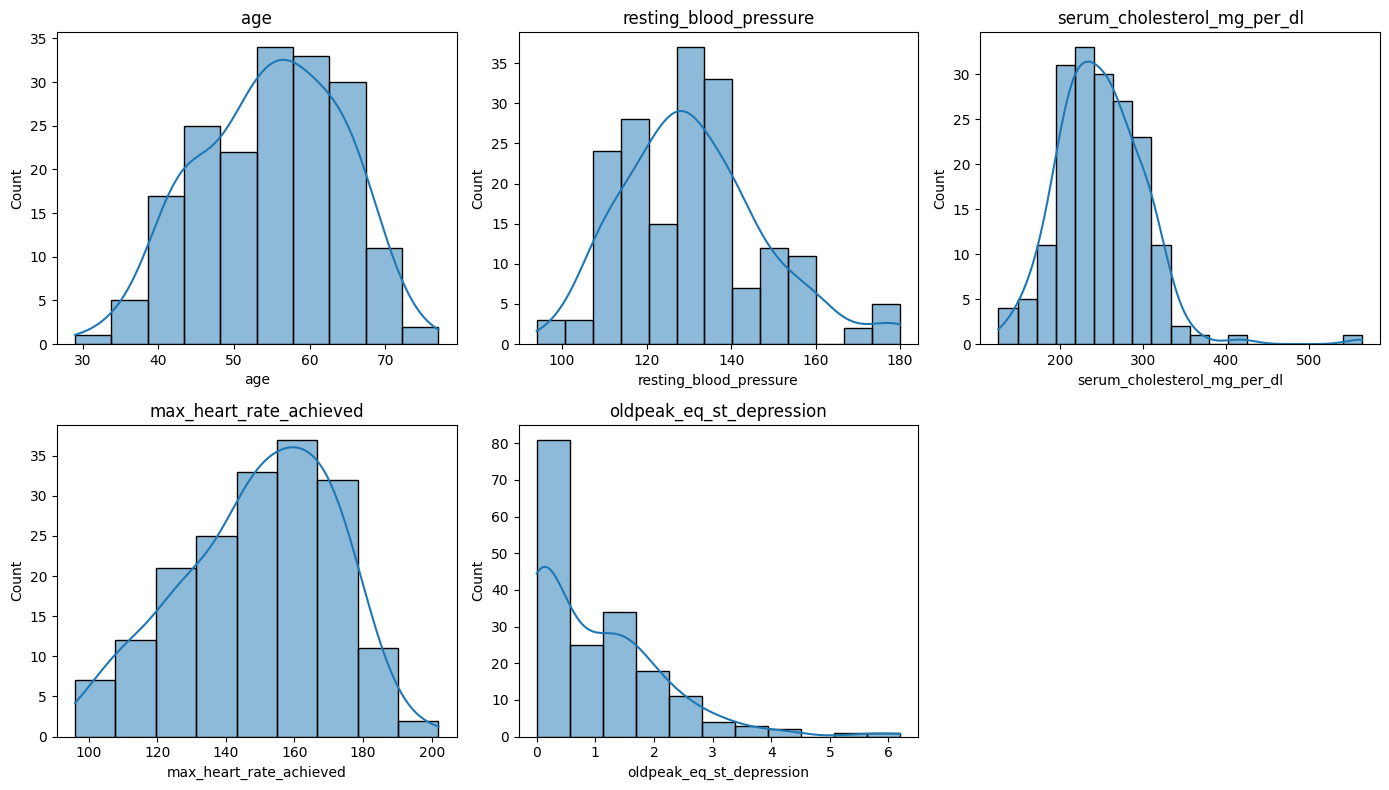

In [28]:
# 7.1 Numerical Feature Distribution

# Histograms are used to understand the distribution of numerical features such as age, blood pressure, cholesterol and heart rate.
num_cols = [
    "age",
    "resting_blood_pressure",
    "serum_cholesterol_mg_per_dl",
    "max_heart_rate_achieved",
    "oldpeak_eq_st_depression"
]

plt.figure(figsize=(14, 8))

i = 1

for col in num_cols:
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(col)
    i = i + 1

plt.tight_layout()
plt.show()

**EDA Insights:**

- **Age:** Most patients are between 45 and 65 years.
- **Resting Blood Pressure:** Most values are concentrated between 110 and 140 mmHg.
- **Cholesterol:** Most patients have levels between 200 and 300 mg/dL, with a few unusually high values.
- **Maximum Heart Rate:** Most patients achieved between 140 and 175 bpm.
- **ST Depression:** The distribution is positively skewed, with most values concentrated near zero.
- Unusually high cholesterol and blood pressure values were identified and will be retained for further analysis.

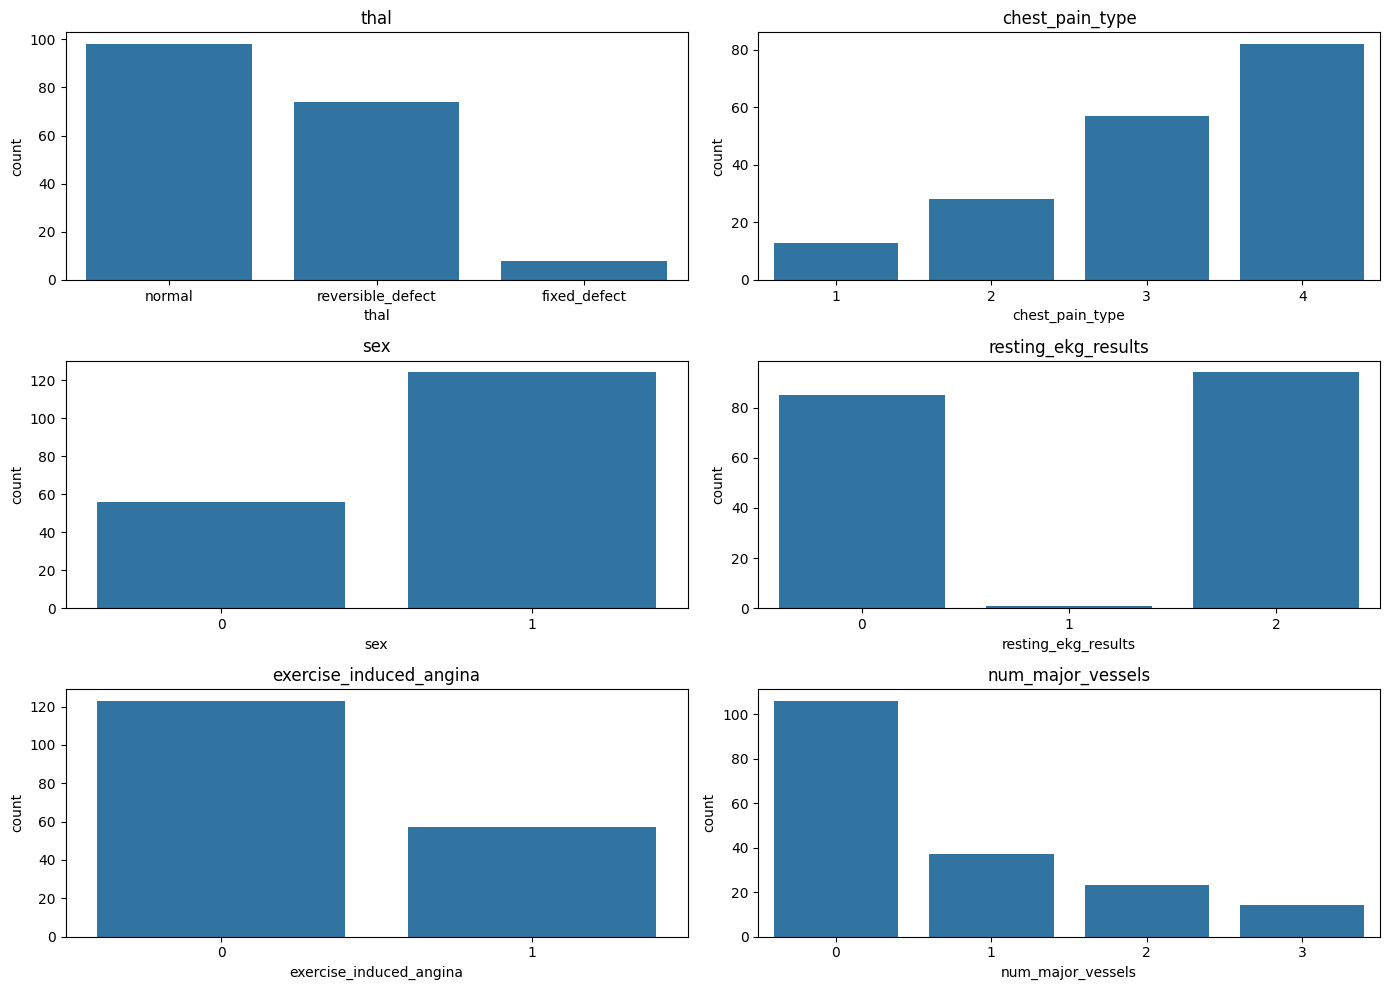

In [29]:
#7.2  Categorical Features
cat_cols = [
    "thal",
    "chest_pain_type",
    "sex",
    "resting_ekg_results",
    "exercise_induced_angina",
    "num_major_vessels"
]

plt.figure(figsize=(14, 10))

i = 1

for col in cat_cols:
    plt.subplot(3, 2, i)
    sns.countplot(data=df, x=col)
    plt.title(col)
    i = i + 1

plt.tight_layout()
plt.show()

**EDA Insights:**

- **Thal:** Normal category has the highest number of patients, followed by reversible defect.
- **Chest Pain Type:** Category 4 is the most frequently observed.
- **Sex:** Male patients (1) are higher in number than female patients (0).
- **Resting ECG:** Categories 0 and 2 are frequently observed, while category 1 is very rare.
- **Exercise-Induced Angina:** Most patients do not experience exercise-induced angina.
- **Major Vessels:** Most patients have zero major vessels, with fewer patients in categories 1, 2 and 3.

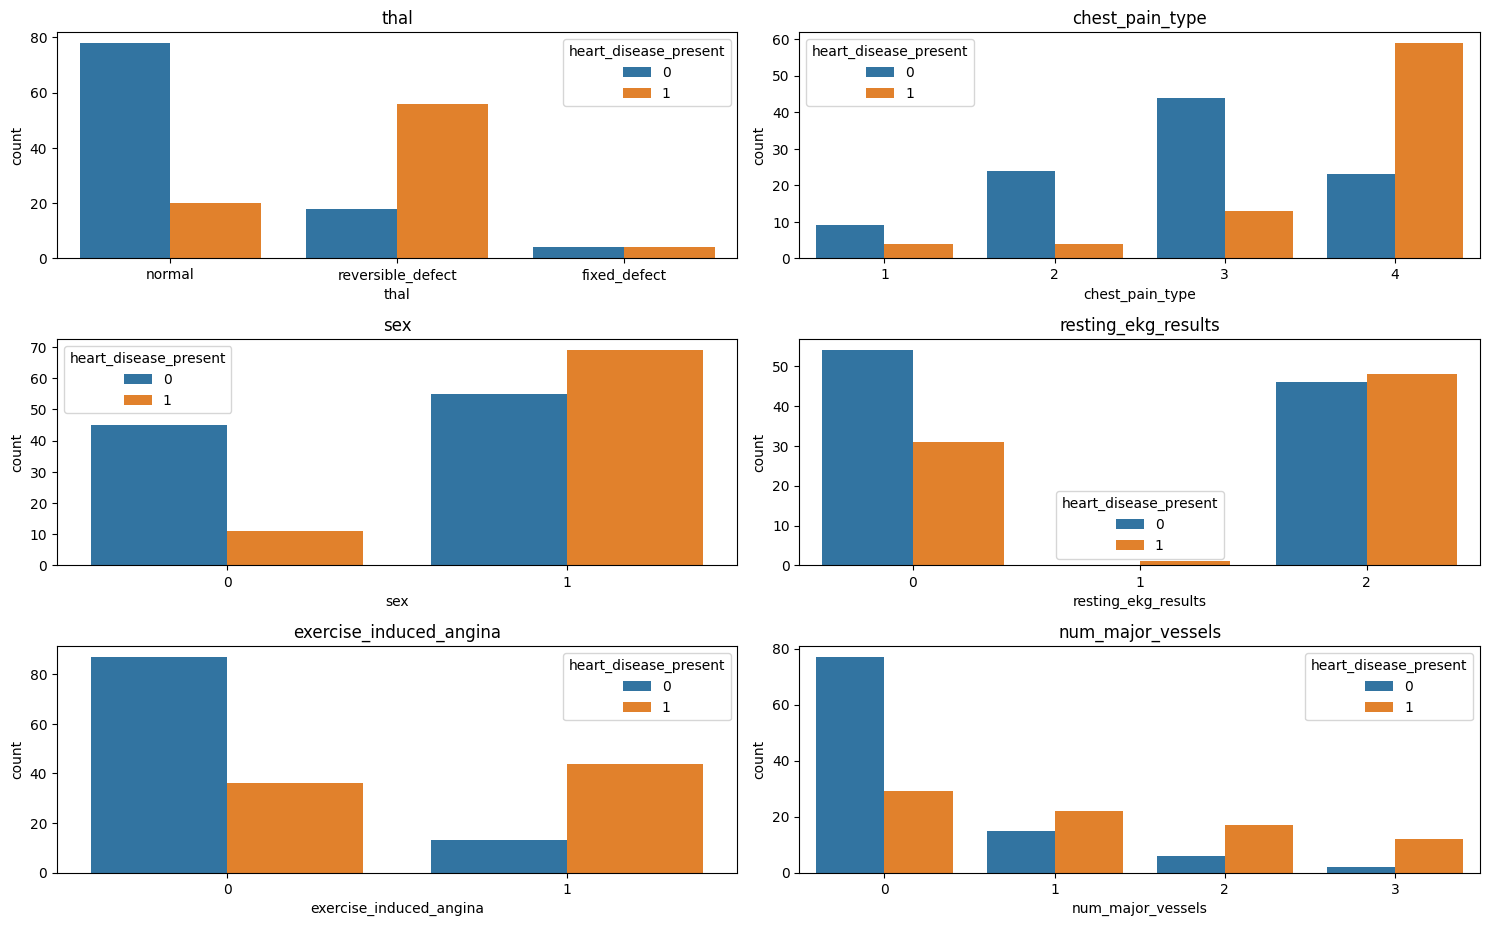

In [30]:
#7.3 Categorical Features vs Heart Disease

cat_cols = [
    "thal",
    "chest_pain_type",
    "sex",
    "resting_ekg_results",
    "exercise_induced_angina",
    "num_major_vessels"
]

plt.figure(figsize=(15, 12))

i = 1

for col in cat_cols:
    plt.subplot(4, 2, i)
    sns.countplot(data=df, x=col, hue="heart_disease_present")
    plt.title(col)
    i = i + 1

plt.tight_layout()
plt.show()

**EDA Insights::**

- **Thal:** Reversible defect has more heart disease cases, while normal has more patients without heart disease.
- **Chest Pain:** Category 4 shows more heart disease cases than patients without heart disease.
- **Sex:** Male patients have a higher number of heart disease cases in this dataset.
- **Resting ECG:** Category 2 shows a slightly higher number of heart disease cases.
- **Exercise-Induced Angina:** Patients with exercise-induced angina show more heart disease cases.
- **Major Vessels:** Higher vessel counts show a greater proportion of heart disease cases in this dataset.

These observations indicate potential relationships between categorical medical features and heart disease.

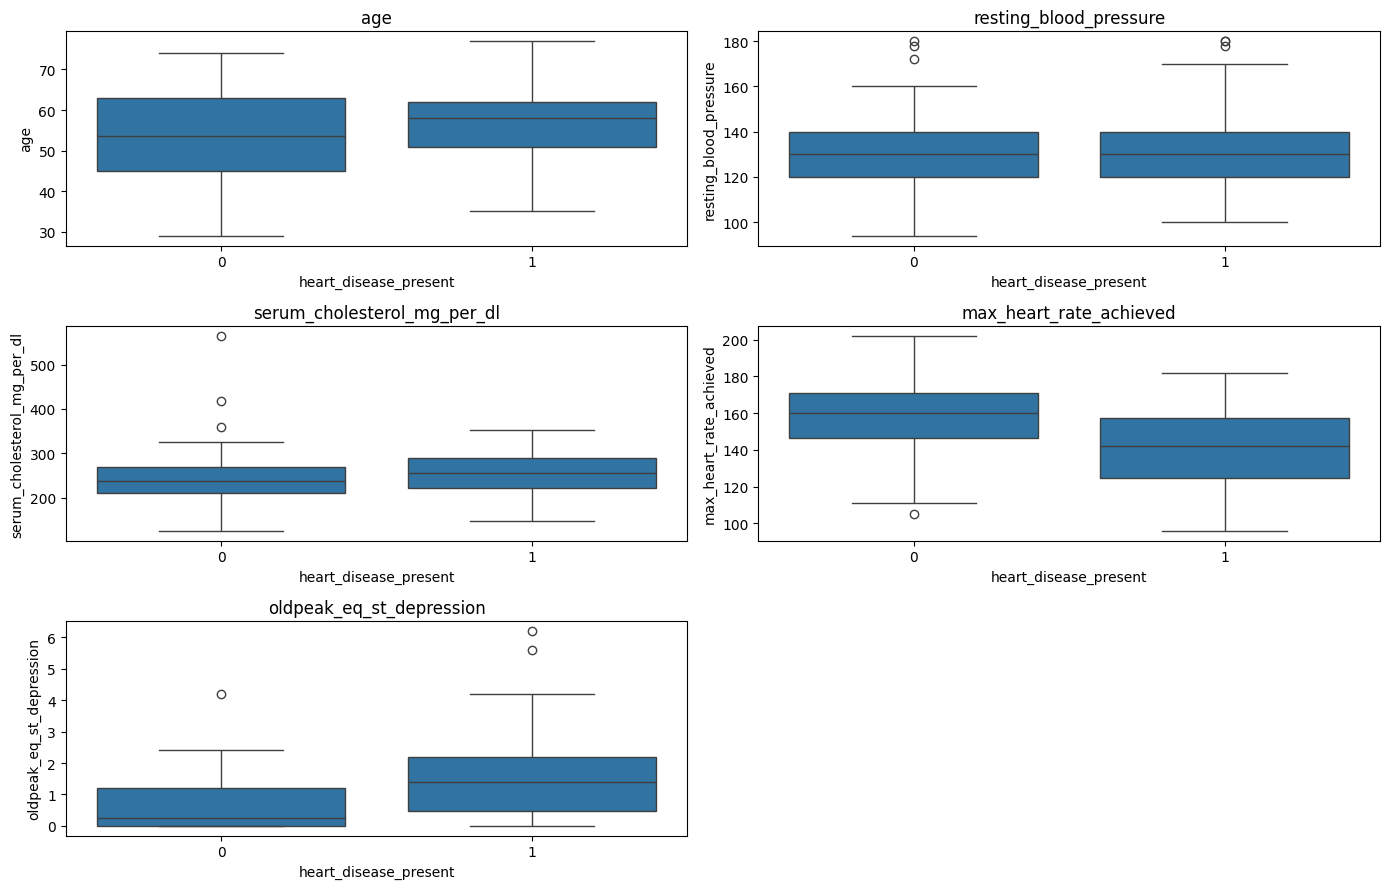

In [31]:
# 7.3 Numerical Features vs Heart Disease

# Box plots are used to compare the distribution of numerical medical features between patients with and without heart disease.
features = [
    "age",
    "resting_blood_pressure",
    "serum_cholesterol_mg_per_dl",
    "max_heart_rate_achieved",
    "oldpeak_eq_st_depression"
]

plt.figure(figsize=(14, 9))

i = 1

for col in features:
    plt.subplot(3, 2, i)
    sns.boxplot(data=df, x="heart_disease_present", y=col)
    plt.title(col)
    i = i + 1

plt.tight_layout()
plt.show()

**EDA Insights::**

- **Age:** Patients with heart disease have a slightly higher median age.
- **Resting Blood Pressure:** Both groups show similar median values, with a few high-value outliers.
- **Cholesterol:** Patients with heart disease have a slightly higher median cholesterol level, while extreme values are observed in the non-heart-disease group.
- **Maximum Heart Rate:** Patients with heart disease generally have lower maximum heart rates.
- **ST Depression:** Patients with heart disease show higher ST depression values, with some extreme observations.

**Key Finding:** Maximum heart rate and ST depression show noticeable differences between the two groups, suggesting potential predictive value.

## 8. EDA Findings

The exploratory data analysis revealed the following important patterns:

1. Most patients in the dataset are between 45 and 65 years old.
2. Cholesterol and resting blood pressure contain some extreme values.
3. Male patients are more represented than female patients.
4. Chest pain category 4 and reversible thal defect show more heart disease cases in this dataset.
5. Patients with heart disease generally show lower maximum heart rates.
6. Higher ST depression values are more frequently observed among patients with heart disease.
7. Exercise-induced angina and the number of major vessels also show differences between the target groups.

These findings provide useful insights into patient characteristics and help guide the machine learning model development process.

## 9. Feature Engineering & Preprocessing

Feature engineering and preprocessing involve preparing the dataset for machine learning. In this section, we separate input features and the target variable and convert categorical features into numerical format where required.

In [32]:
#9.1 Separate Input Features and Target

x=df.drop(columns=["patient_id", "heart_disease_present"])
y=df["heart_disease_present"]

print("Input Features shape:-",x.shape)
print("Target Features shape:-",y.shape)

Input Features shape:- (180, 13)
Target Features shape:- (180,)


In [33]:
# 9.2 – Encode the text categorical column
x=pd.get_dummies(x,columns=["thal"], drop_first=True, dtype=int)
print(x.shape)
display(x.head())

(180, 14)


,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,thal_normal,thal_reversible_defect
0,1,128,2,0,0,2,308,0.0,1,45,170,0,1,0
1,2,110,3,0,0,0,214,1.6,0,54,158,0,1,0
2,1,125,4,3,0,2,304,0.0,1,77,162,1,1,0
3,1,152,4,0,0,0,223,0.0,1,40,181,0,0,1
4,3,178,1,0,0,2,270,4.2,1,59,145,0,0,1


## 10. Train-Test Split & Model Building

In this section, the dataset is divided into training and testing sets using an 80:20 ratio. Five machine learning classification algorithms are trained to predict the presence of heart disease.

Feature scaling is applied to algorithms that require it, such as Logistic Regression, KNN and SVM. Training and testing accuracy are compared to understand model performance and identify potential overfitting or underfitting.

In [34]:
# Train-Test Split 
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (144, 14)
Testing Data: (36, 14)


In [35]:
# Feature Scaling
scaler=StandardScaler()
x_train_scale= scaler.fit_transform(X_train)
x_test_scales=scaler.transform(X_test)

In [36]:
# Model cration and training vs testing acuuracy

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB()
}

results = []

for name, model in models.items():

    if name in ["Logistic Regression", "KNN", "SVM"]:
        model.fit(x_train_scale, y_train)
        train_pred = model.predict(x_train_scale)
        test_pred = model.predict(x_test_scales)

    else:
        model.fit(X_train, y_train)
        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc
    })

    print(name,":")
    print("Training Accuracy:", round(train_acc, 3))
    print("Testing Accuracy:", round(test_acc, 3))
    print("-" * 30)

Logistic Regression :
Training Accuracy: 0.847
Testing Accuracy: 0.833
------------------------------
KNN :
Training Accuracy: 0.868
Testing Accuracy: 0.833
------------------------------
Decision Tree :
Training Accuracy: 1.0
Testing Accuracy: 0.806
------------------------------
Random Forest :
Training Accuracy: 1.0
Testing Accuracy: 0.861
------------------------------
SVM :
Training Accuracy: 0.917
Testing Accuracy: 0.861
------------------------------
Naive Bayes :
Training Accuracy: 0.84
Testing Accuracy: 0.861
------------------------------


**FINDING:**

Six classification algorithms were trained and evaluated using training and testing datasets. Random Forest, SVM and Naive Bayes achieved the highest testing accuracy of 86.1%.

Decision Tree and Random Forest achieved 100% training accuracy, indicating possible overfitting. Further evaluation using precision, recall, F1-score and confusion matrices is required before selecting the final model.

## 11. Model Evaluation & Comparison

In this section, the trained classification models are evaluated using multiple performance metrics. These metrics help compare model performance and identify the most suitable candidates for heart disease prediction.

In [37]:
evaluation = []

for name, model in models.items():

    if name in ["Logistic Regression", "KNN", "SVM"]:
        y_pred = model.predict(x_test_scales)
    else:
        y_pred = model.predict(X_test)

    evaluation.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

evaluation_df = pd.DataFrame(evaluation)

display(evaluation_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.833,0.778,0.875,0.824
1,KNN,0.833,0.778,0.875,0.824
2,Decision Tree,0.806,0.765,0.812,0.788
3,Random Forest,0.861,0.789,0.938,0.857
4,SVM,0.861,0.824,0.875,0.848
5,Naive Bayes,0.861,0.789,0.938,0.857


### Findings

1. Random Forest, SVM, and Naive Bayes achieved the highest testing accuracy of **86.1%**.
2. Random Forest and Naive Bayes achieved the highest Recall of **93.8%** and F1 Score of **85.7%**.
3. SVM achieved the highest Precision of **82.4%**.
4. Decision Tree showed the lowest testing accuracy of **80.6%**.
5. Random Forest achieved 100% training accuracy but 86.1% testing accuracy, indicating possible overfitting.

**Initial Model Selection:**

Random Forest is selected as the initial best model because of its high Recall and F1 Score. Hyperparameter tuning will be performed to reduce possible overfitting and improve model performance.

## 12. Hyperparameter Tuning – Random Forest

GridSearchCV is used to find the best hyperparameters for the Random Forest model using 5-fold cross-validation. The objective is to reduce overfitting and improve model performance.

In [38]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5],
    "min_samples_leaf": [1, 2],
    "min_samples_split": [2]
}


rf=RandomForestClassifier(random_state=42)

grid=GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring="f1"
)

grid.fit(X_train,y_train)

best_rf=grid.best_estimator_
print("Best Parameters:", grid.best_params_)
print("Best CV F1 Score:", round(grid.best_score_, 3))

train_pred = best_rf.predict(X_train)
test_pred = best_rf.predict(X_test)

print("Training Accuracy:", round(accuracy_score(y_train, train_pred), 3))
print("Testing Accuracy:", round(accuracy_score(y_test, test_pred), 3))
print("Precision:", round(precision_score(y_test, test_pred), 3))
print("Recall:", round(recall_score(y_test, test_pred), 3))
print("F1 Score:", round(f1_score(y_test, test_pred), 3))

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1 Score: 0.791
Training Accuracy: 0.924
Testing Accuracy: 0.917
Precision: 0.842
Recall: 1.0
F1 Score: 0.914


### Final Findings

1. The original Random Forest achieved 100% training accuracy but only 86.1% testing accuracy, indicating possible overfitting.
2. Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation to improve the model's generalization.
3. The tuned Random Forest achieved 92.4% training accuracy and 91.7% testing accuracy, showing a smaller gap between training and testing performance.
4. The tuned model achieved 84.2% Precision, 100% Recall, and 91.4% F1 Score.
5. Naive Bayes achieved an F1 Score of 85.7%, whereas the tuned Random Forest achieved 91.4%.


The tuned Random Forest is selected as the final model because it achieved higher testing accuracy and F1 Score than Naive Bayes, along with 100% Recall on the test dataset. It also showed reduced overfitting compared with the original Random Forest.

## 13. Final Model Selection

The tuned Random Forest model is selected as the final model based on its evaluation results.

- Training Accuracy: 92.4%
- Testing Accuracy: 91.7%
- Precision: 84.2%
- Recall: 100%
- F1 Score: 91.4%

The model demonstrated good performance on the test dataset and identified all actual heart disease cases in the test set. Therefore, it is selected as the final model for this project.

## 14. Hospital Recommendations

Based on the data analysis, EDA findings, and machine learning model results, the following recommendations are suggested for hospitals:

1. **Focus on Early Screening:** Since 44.4% of the 180 patients in the dataset were identified as having heart disease, hospitals should encourage regular cardiovascular screening and early medical evaluation.

2. **Monitor Important Health Indicators:** The analysis showed an average resting blood pressure of 131 mmHg and average cholesterol level of 249 mg/dL. Hospitals should monitor these indicators during routine health checkups.

3. **Evaluate Chest Pain Symptoms:** Chest pain category 4 showed more heart disease cases in the dataset. Patients reporting chest pain should receive appropriate medical evaluation.

4. **Monitor Cardiac Symptoms:** Exercise-induced angina, higher ST depression, and lower maximum heart rate showed differences between patients with and without heart disease. These indicators can help guide further clinical assessment.

5. **Use ML for Risk Assessment Support:** The selected Random Forest model achieved 91.7% testing accuracy and 100% Recall on the test dataset. It may be explored as an additional screening support tool to identify patients who need further medical evaluation.

6. **Promote Preventive Healthcare:** Hospitals should conduct awareness programs focusing on blood pressure, cholesterol management, healthy lifestyles, and regular medical checkups.

**Expected Benefits:**

- Better understanding of patient risk indicators.
- Support for identifying potentially high-risk patients.
- Encouragement of early medical evaluation.
- Improved focus on preventive healthcare.

## 15. Challenges, Limitations & Conclusion

### 15.1 Challenges Faced

1. **Data Integration:** Combined two separate datasets using `patient_id` to create a single dataset for analysis.
2. **Categorical Data Handling:** Converted the categorical `thal` feature into numerical format using One-Hot Encoding.
3. **Model Selection:** Compared six classification algorithms to identify a suitable model for heart disease prediction.
4. **Overfitting:** The original Random Forest showed 100% training accuracy. Hyperparameter tuning was performed to improve generalization.
5. **Model Evaluation:** Compared models using Accuracy, Precision, Recall, and F1 Score to identify the best-performing model.

### 15.2 Project Limitations

1. The dataset contains only 180 patient records, which is relatively small for building a reliable prediction model.
2. The model performance may vary when tested on new patient data.
3. The dataset may not represent all patient populations.
4. The model has not been clinically validated and should not replace professional medical diagnosis.

### 15.3 Conclusion

This project focused on analyzing patient health information and developing a machine learning model to predict the presence of heart disease.

Exploratory Data Analysis helped identify important patterns and differences between patients with and without heart disease.

Six classification algorithms were compared, and the tuned Random Forest model was selected as the final model.

The selected model achieved:

- Training Accuracy: 92.4%
- Testing Accuracy: 91.7%
- Precision: 84.2%
- Recall: 100%
- F1 Score: 91.4%

The project demonstrates how data analysis and machine learning can support the identification of potentially high-risk patients and help hospitals focus on early screening and preventive healthcare.

**Overall, this project provided practical experience in data cleaning, EDA, feature preprocessing, model building, evaluation, and hyperparameter tuning.**